# Week 7 group project: Segmentation
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%207/Week7_Starter_Segmentation.ipynb)

**Your group's mission:** build a very simple app (an MVP) that does
**segmentation: giving every pixel of a photo a label** on photos you take yourselves, in or outside the school, find out how
good it is, and teach the rest of the class about it.

*Question for your group: which pixels belong to what - and how much of the photo is it?*

**Timeline**

| Time | What |
|------|------|
| 10:45-11:30 | **Phase 1 (45 min):** take photos and come up with your MVP - no laptops needed (read sections 1 and 3 for ideas) |
| 11:30 | **Stand-up:** 3 minutes per group - your MVP idea, your photos, who does what |
| 12:00-14:30 | **Phase 2:** photos into Colab, build the MVP and make it work, ground truth, evaluation, presentation (sections 0-8) |
| 14:45-15:30 | **Presentations:** your MVP, 10 minutes per group + 3 minutes questions |

**Your presentation must explain**

1. **What the technique is** - what goes in, what comes out, what it is used for (section 1)
2. **What data processing is needed** - from a phone photo to something the model can use, and the ground truth (sections 4 and 6)
3. **What you did** - your idea, your photos, how you built your MVP (sections 3 and 5)
4. **How you evaluate it** - which metric, why, and your result (section 7)
5. **The end result: your MVP** - show it working, and where it fails (section 8)

**Organise your group.** You are a big group, so split the work. A split
that works: a **photo team** (collects photos, makes the ground truth), a
**build team** (runs this notebook, builds the MVP), an **evaluation team**
(chooses and calculates the metric), and a **presentation team** (slides,
demo, timing). Pick one person who keeps an eye on the clock. Share this
notebook through Google Drive so everybody can see it.

# Week 7 group project: Segmentation
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%207/Week7_Starter_Segmentation.ipynb)

**Your group's mission:** build a very simple app (an MVP) that does
**segmentation: giving every pixel of a photo a label** on photos you take yourselves, in or outside the school, find out how
good it is, and teach the rest of the class about it.

*Question for your group: which pixels belong to what - and how much of the photo is it?*

**Timeline**

| Time | What |
|------|------|
| 10:45-11:30 | **Phase 1 (45 min):** take photos and come up with your MVP - no laptops needed (read sections 1 and 3 for ideas) |
| 11:30 | **Stand-up:** 3 minutes per group - your MVP idea, your photos, who does what |
| 12:00-14:30 | **Phase 2:** photos into Colab, build the MVP and make it work, ground truth, evaluation, presentation (sections 0-8) |
| 14:45-15:30 | **Presentations:** your MVP, 10 minutes per group + 3 minutes questions |

**Your presentation must explain**

1. **What the technique is** - what goes in, what comes out, what it is used for (section 1)
2. **What data processing is needed** - from a phone photo to something the model can use, and the ground truth (sections 4 and 6)
3. **What you did** - your idea, your photos, how you built your MVP (sections 3 and 5)
4. **How you evaluate it** - which metric, why, and your result (section 7)
5. **The end result: your MVP** - show it working, and where it fails (section 8)

**Organise your group.** You are a big group, so split the work. A split
that works: a **photo team** (collects photos, makes the ground truth), a
**build team** (runs this notebook, builds the MVP), an **evaluation team**
(chooses and calculates the metric), and a **presentation team** (slides,
demo, timing). Pick one person who keeps an eye on the clock. Share this
notebook through Google Drive so everybody can see it.

## 0. Setup - run these cells once

The first cell is only needed for iPhone photos in HEIC format (or set the
iPhone camera to *Settings -> Camera -> Formats -> Most Compatible*). The
second cell loads the tools and some helpers:

- `upload_to("photos")` - choose photos on your laptop; they land in the folder `photos`
- `take_photo("photos", "name.jpg")` - take a photo with the laptop camera
- `load_folder("photos")` - load all photos of a folder: turned the right way up and made smaller
- `show([...])` - show pictures next to each other
- `save_result(name)` - save the picture you just made in the folder `results`, for your slides
- `download_results()` - download the folder `results` as a zip

In [21]:
%pip install -q truststore

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import truststore
truststore.inject_into_ssl()

import urllib.request

print("SSL setup ready")

SSL setup ready


In [9]:
# Only needed for iPhone HEIC photos
!pip install -q pillow-heif


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\milou\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [11]:
# Run, do not read
import warnings
warnings.filterwarnings("ignore")
import os, glob, base64, shutil, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import torch
import torchvision.transforms.functional as TF
torch.set_grad_enabled(False)
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass
os.makedirs("results", exist_ok=True)

def show(images, titles=None, size=3.5):
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    if len(images) == 1:
        axes = [axes]
    for k in range(len(images)):
        axes[k].imshow(images[k], cmap="gray" if images[k].ndim == 2 else None)
        axes[k].axis("off")
        if titles:
            axes[k].set_title(titles[k], fontsize=9)
    plt.show()

def save_result(name):
    # call this INSIDE the same cell, right after a picture is drawn
    plt.savefig(os.path.join("results", name), dpi=120, bbox_inches="tight")
    print("saved results/" + name)

def download_results():
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")

def upload_to(folder):
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, content in files.upload().items():
        with open(os.path.join(folder, name), "wb") as f:
            f.write(content)

def take_photo(folder, name):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    os.makedirs(folder, exist_ok=True)
    display(Javascript('''
    async function takePhoto() {
      const div = document.createElement('div');
      const button = document.createElement('button');
      button.textContent = 'Capture';
      div.appendChild(button);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.9);
    }'''))
    data_url = eval_js("takePhoto()")
    with open(os.path.join(folder, name), "wb") as f:
        f.write(base64.b64decode(data_url.split(",")[1]))
    print("saved", os.path.join(folder, name))

def load_folder(folder, max_size=1024):
    photos = {}
    for f in sorted(glob.glob(os.path.join(folder, "*"))):
        if "_mask" in os.path.basename(f):
            continue
        try:
            im = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
        except Exception:
            print("skipped (not a photo):", f)
            continue
        im.thumbnail((max_size, max_size))
        photos[os.path.basename(f)] = np.array(im)
    print(folder, ":", len(photos), "photos")
    return photos

def download_examples(folder, urls):
    os.makedirs(folder, exist_ok=True)
    for url in urls:
        target = os.path.join(folder, url.split("/")[-1])
        if not os.path.exists(target):
            urllib.request.urlretrieve(url, target)

print("Ready")

Ready


## 1. What is segmentation?

Segmentation gives **every pixel** a label. The result is a **mask**: a grid
of True/False, as big as the photo. Because a mask follows the exact outline,
you can **measure an area**: how much of the photo is grass, people, bicycles?

- **Semantic segmentation:** every pixel gets a class ("person"), but two people
  next to each other are one blob.
- **Instance segmentation:** every object gets its own mask ("person 1",
  "person 2"), so you can also count.

You have two pre-trained models (run the cell):

| Model | What it can segment | How you ask |
|-------|---------------------|-------------|
| **Mask R-CNN** (instance, COCO) | 80 fixed kinds: person, car, bicycle, chair, potted plant, ... | `segment(photo, "person")` |
| **CLIPSeg** (semantic, by text) | anything you describe in words: grass, trees, road, sky, litter, ... | `segment(photo, "grass", model="text")` |

Segmentation is an AI technique that identifies which pixels in an image belong to an object.

Object detection draws a box around an object, while segmentation creates a mask that follows the object's shape.

Semantic segmentation gives pixels of the same category the same label. Instance segmentation can distinguish between different objects of the same category.

Segmentation can be useful in healthcare, self-driving cars and environmental monitoring.

In [12]:
# Run, do not read: two pre-trained segmentation models
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation
coco_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
coco_model = maskrcnn_resnet50_fpn(weights=coco_weights).eval()
COCO = coco_weights.meta["categories"]
clip_processor = CLIPSegProcessor.from_pretrained("CIDAS/clipseg-rd64-refined")
clip_model = CLIPSegForImageSegmentation.from_pretrained("CIDAS/clipseg-rd64-refined")

def segment(picture, what, model="coco", threshold=0.5):
    if model == "coco":
        out = coco_model([TF.to_tensor(picture)])[0]
        mask = np.zeros(picture.shape[:2], dtype=bool)
        for m, lab, score in zip(out["masks"], out["labels"], out["scores"]):
            if score >= threshold and COCO[int(lab)] == what:
                mask |= m[0].numpy() > 0.5
        return mask
    inputs = clip_processor(text=[what], images=[Image.fromarray(picture)], return_tensors="pt")
    heat = torch.sigmoid(clip_model(**inputs).logits).numpy().reshape(352, 352)
    heat = np.array(Image.fromarray((heat * 255).astype("uint8")).resize((picture.shape[1], picture.shape[0])))
    return heat / 255 >= threshold

def overlay(picture, mask, title=""):
    view = picture.astype(float) / 255
    view[mask] = 0.4 * view[mask] + 0.6 * np.array([1.0, 0.1, 0.6])
    plt.figure(figsize=(6, 5))
    plt.imshow(view)
    plt.axis("off")
    plt.title(title)

print("COCO knows:", [n for n in COCO if n not in ("__background__", "N/A")])

Loading weights: 100%|██████████| 462/462 [00:00<00:00, 502.07it/s]


COCO knows: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


## 2. Try it now

One example photo, both models: the bicycle with Mask R-CNN, the road with
CLIPSeg, and how much of the photo each one covers.

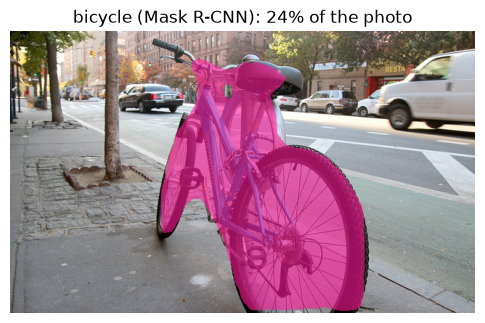

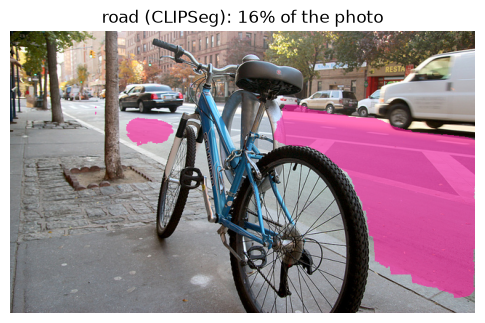

In [13]:
street = np.array(Image.open(urllib.request.urlopen("http://images.cocodataset.org/val2017/000000174482.jpg")).convert("RGB"))
bike = segment(street, "bicycle")
overlay(street, bike, "bicycle (Mask R-CNN): " + str(round(100 * bike.mean())) + "% of the photo")
plt.show()
road = segment(street, "road", model="text", threshold=0.4)
overlay(street, road, "road (CLIPSeg): " + str(round(100 * road.mean())) + "% of the photo")
plt.show()

## 3. Your photos

**Ideas** (or think of your own):

- *Green campus meter:* how much of the view around the school is trees and grass?
- *Bike shed meter:* how much of the shed is filled with bicycles?
- *Busy meter:* how much of the canteen or corridor is people?
- *Litter meter:* how much of the floor or the square is covered in litter?
- *Sky meter:* how much daylight does a classroom window let in?

Decide **what** your app measures, and **for whom**. Then go and take photos.

**Rules for taking photos**

- **People only with permission.** Only photograph people who say yes - accept
  a no. Other people in the school must not be recognisable: aim away, or
  photograph them from behind.
- **Never put photos of people online.** Not in your portfolio (it is public)
  and not in a shared folder outside the group. Before you upload this notebook
  anywhere: *Edit -> Clear all outputs*. Delete the photos after this week.
- **Make it hard for the model.** Different places, light, distances and
  angles, and a few difficult photos (crowded, dark, half hidden). A test with
  only easy photos tells you nothing.
- **Enough photos:** at least 10, more is better. Any phone photo works.

**Getting your photos into Colab:** `upload_to("photos")` from the laptop
(send them from your phone by AirDrop, e-mail or Google Drive first), drag a
zip into the file panel on the left and run `!unzip -q yourfile.zip -d photos`,
or use the laptop camera with `take_photo("photos", "name.jpg")`.

photos : 20 photos


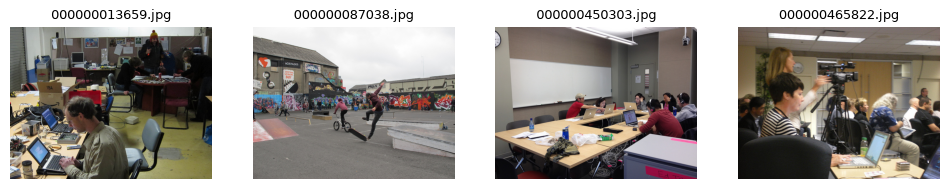

In [25]:
# upload_to("photos")                         # or a zip, or take_photo(...)
folder = "photos"
what = "person"           # what your app measures
model = "coco"            # "coco" for the 80 COCO objects, "text" for anything else
threshold = 0.5

# No photos yet? 4 example street photos with hand-made masks let you test everything first.
# Delete these lines once your own photos (and masks) are in the folder "photos".
if not os.path.exists("PennFudanPed"):
    zipfile.ZipFile("PennFudanPed.zip").extractall(".")
os.makedirs("photos", exist_ok=True)
for f in sorted(glob.glob("PennFudanPed/PNGImages/*.png"))[:4]:
    name = os.path.basename(f)
    Image.open(f).convert("RGB").save(os.path.join("photos", name))
    ids = np.array(Image.open(f.replace("PNGImages", "PedMasks").replace(".png", "_mask.png")))
    red = np.zeros(ids.shape + (3,), dtype="uint8")
    red[ids > 0] = [255, 0, 0]
    Image.fromarray(red).save(os.path.join("photos", name.replace(".png", "_mask.png")))

photos = load_folder(folder)
show([photos[n] for n in photos][:4], list(photos)[:4], size=3)

## 4. Data processing

A phone photo is not ready for a model. Run the cell: it shows what happens to
one of your photos on its way in. **Use this for part 2 of your
presentation.**

1. the file from the phone:      640 x 480 pixels, RGB
2. turned the right way up:      no rotation needed (phones store the rotation separately, in the EXIF data)
3. made smaller (max 1024):      640 x 480 pixels
4. a grid of numbers:            (480, 640, 3) = 921600 numbers from 0 to 255
5. scaled to 0-1 for the model:  0.0 to 1.0


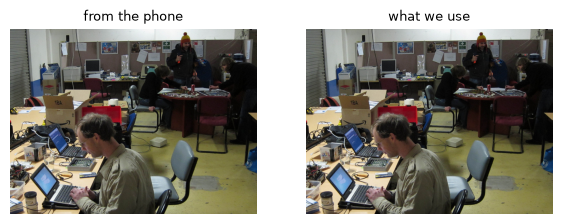

In [26]:
# Run, do not read: what happens to a phone photo before the model sees it
name = list(photos)[0]
original = Image.open(glob.glob(os.path.join(folder, name))[0])
print("1. the file from the phone:     ", original.size[0], "x", original.size[1], "pixels,", original.mode)
upright = ImageOps.exif_transpose(original)
print("2. turned the right way up:     ", "yes" if upright.size != original.size else "no rotation needed",
      "(phones store the rotation separately, in the EXIF data)")
print("3. made smaller (max 1024):     ", photos[name].shape[1], "x", photos[name].shape[0], "pixels")
print("4. a grid of numbers:           ", photos[name].shape, "=", photos[name].size, "numbers from 0 to 255")
x = TF.to_tensor(photos[name])
print("5. scaled to 0-1 for the model: ", round(float(x.min()), 2), "to", round(float(x.max()), 2))
show([np.array(original.convert("RGB")), photos[name]], ["from the phone", "what we use"])

### Data processing explanation

Before an image can be used by the segmentation model, it needs to be prepared. The image is rotated correctly, resized to a maximum of 1024 pixels and converted into numerical pixel values.

The pixel values are scaled from 0–255 to 0–1 so the model can process them.

The model then predicts which pixels belong to a person.

**For segmentation the ground truth is the most work** (section 6): you
paint the true mask yourself, pixel by pixel. And the model's mask must be
turned back to the size of the photo before you can compare (the CLIPSeg mask
is only 352 x 352 pixels; the helper resizes it).

## 5. Your MVP

Change `my_app` so it answers your question in a sentence, then run it on all
your photos.

000000013659.jpg -> People cover 20.3% of the photo.


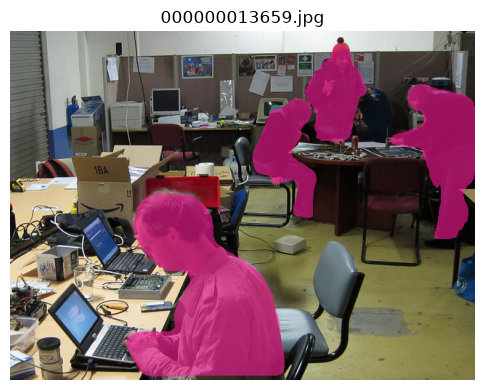

000000087038.jpg -> People cover 4.0% of the photo.


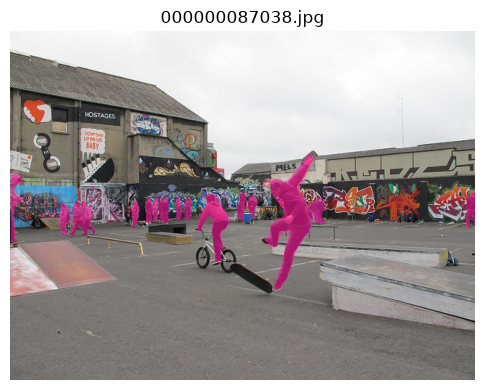

000000450303.jpg -> People cover 7.5% of the photo.


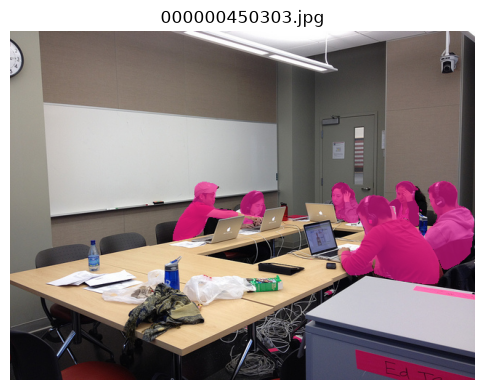

000000465822.jpg -> People cover 24.4% of the photo.


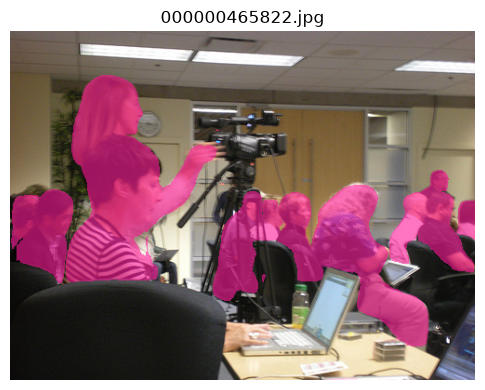

FudanPed00001.png -> People cover 10.4% of the photo.


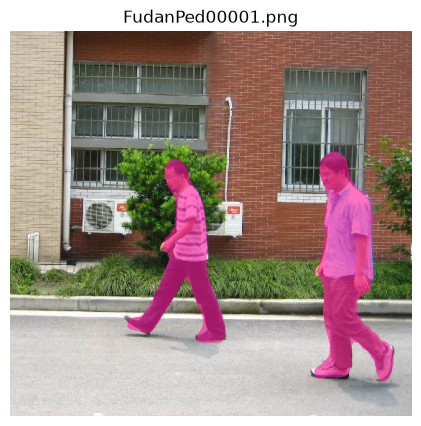

FudanPed00002.png -> People cover 12.2% of the photo.


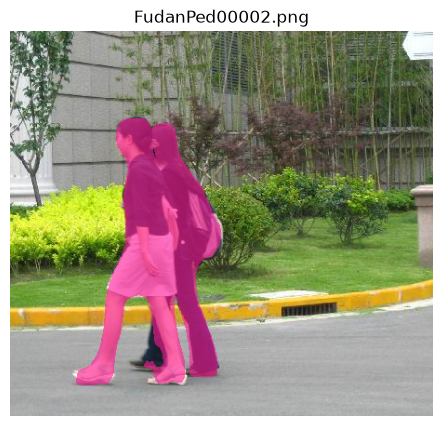

FudanPed00003.png -> People cover 8.5% of the photo.


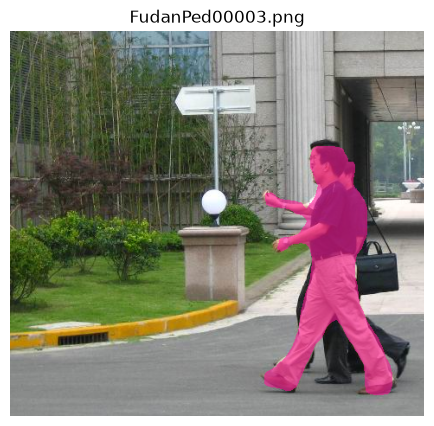

FudanPed00004.png -> People cover 13.7% of the photo.


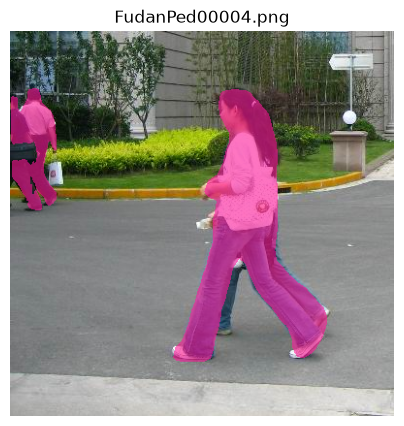

no_13177.jpg -> People cover 20.3% of the photo.


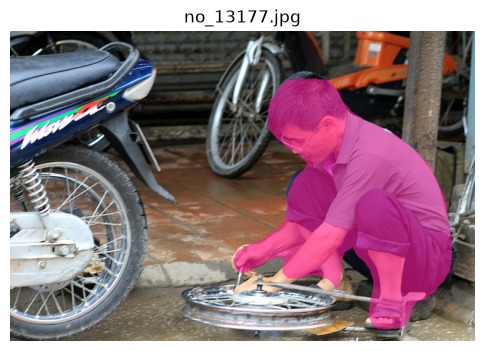

no_327601.jpg -> People cover 22.0% of the photo.


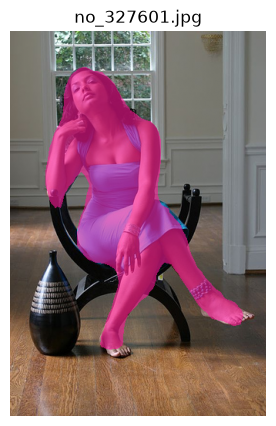

no_365642.jpg -> People cover 25.4% of the photo.


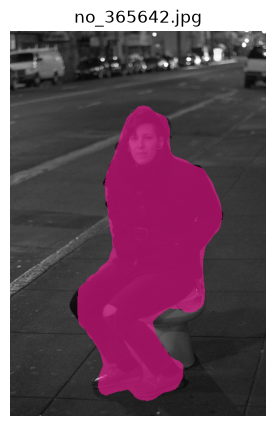

no_481386.jpg -> People cover 17.9% of the photo.


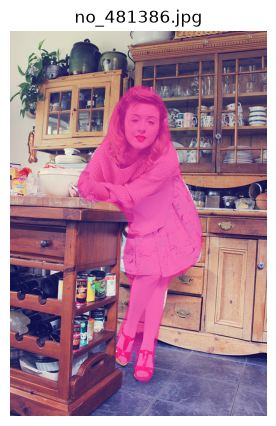

no_547336.jpg -> People cover 25.3% of the photo.


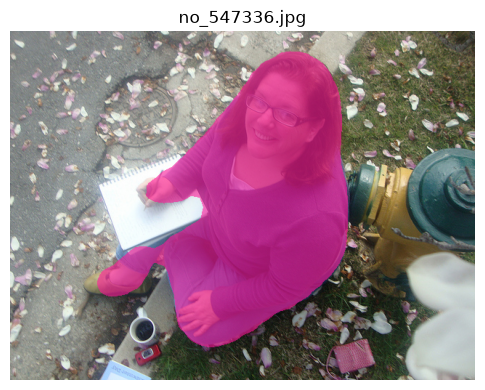

no_67180.jpg -> People cover 19.0% of the photo.


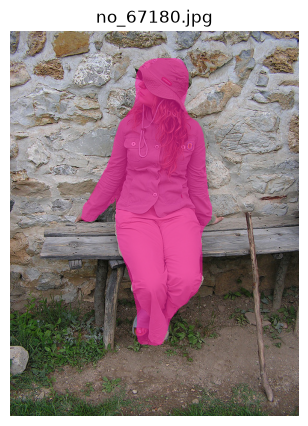

yes_154425.jpg -> People cover 12.8% of the photo.


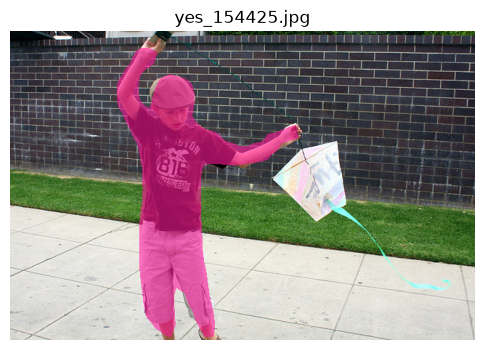

yes_199055.jpg -> People cover 22.2% of the photo.


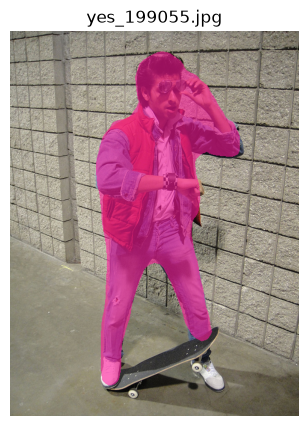

yes_444142.jpg -> People cover 14.1% of the photo.


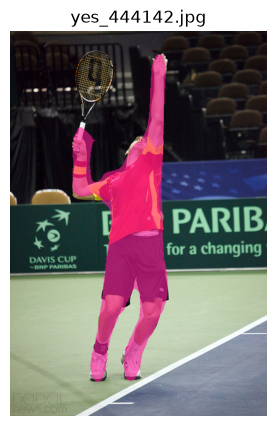

yes_445792.jpg -> People cover 54.3% of the photo.


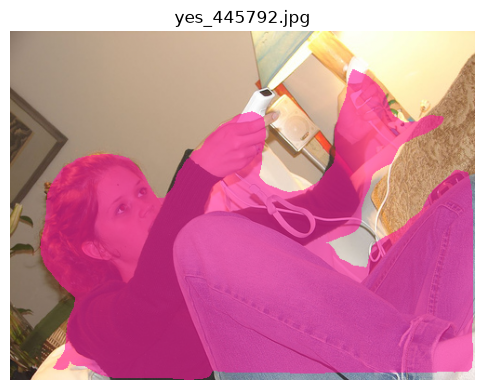

yes_546717.jpg -> People cover 22.7% of the photo.


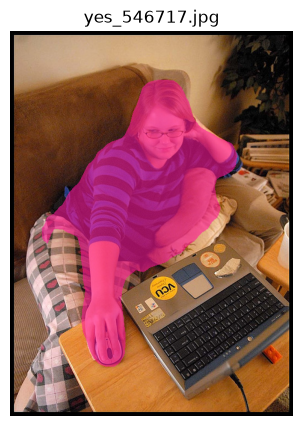

yes_72281.jpg -> People cover 18.6% of the photo.


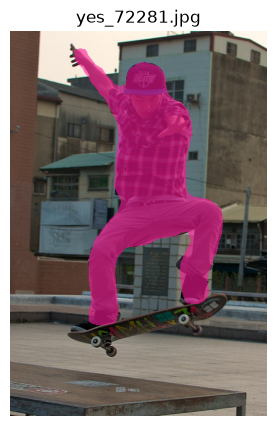

In [27]:
def my_app(picture, name=""):
    mask = segment(picture, what, model, threshold)
    share = round(100 * float(mask.mean()), 1)
    overlay(picture, mask, name)
    return "People cover " + str(share) + "% of the photo."

for name in photos:
    print(name, "->", my_app(photos[name], name))
    plt.show()

## 6. Ground truth: paint the masks

1. Open a photo in **Paint** (Windows), **Photopea** (photopea.com, free, in
   the browser) or any drawing app.
2. Paint **every pixel of your object pure red** (red 255, green 0, blue 0)
   with the brush or the fill tool. Leave the rest as it is.
3. Save it as PNG with `_mask` added: `canteen1.jpg` -> `canteen1_mask.png`.
4. Upload the masks to the same folder `photos`.

At least 4 masks; split the work, and agree first on the rules (does a bag
count as part of the person? the gap between the legs?).

4 painted masks: ['FudanPed00001.png', 'FudanPed00002.png', 'FudanPed00003.png', 'FudanPed00004.png']


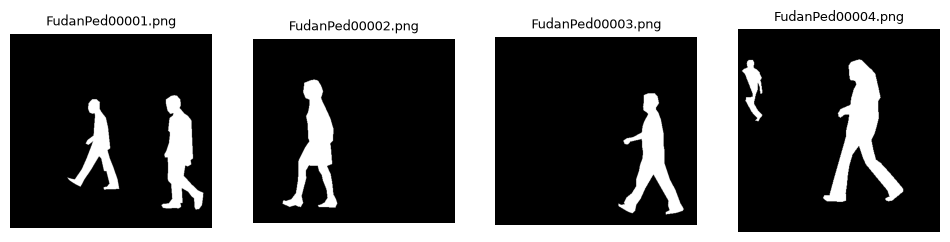

In [28]:
# Run, do not read: load the painted masks
def read_mask(name):
    path = os.path.join(folder, os.path.splitext(name)[0] + "_mask.png")
    if not os.path.exists(path):
        return None
    painted = np.array(Image.open(path).convert("RGB").resize((photos[name].shape[1], photos[name].shape[0]), Image.NEAREST)).astype(int)
    return (painted[:, :, 0] > 200) & (painted[:, :, 1] < 80) & (painted[:, :, 2] < 80)

truth = {}
for name in photos:
    m = read_mask(name)
    if m is not None:
        truth[name] = m
print(len(truth), "painted masks:", list(truth))
show([truth[n] for n in truth][:4], list(truth)[:4], size=3)

## 7. Evaluate

- **Mask IoU** = pixels in both masks / pixels in either mask (1 = perfect)
- **Dice** = 2 x pixels in both / (pixels in mask A + pixels in mask B)
- **Area error** = the share according to you minus the share according to the
  model, in percentage points - what the user of your meter notices

The second cell compares the two models and several thresholds. The third
shows where it goes wrong: **green** = right, **red** = missed, **blue** =
painted by the model but not by you.

In [29]:
# Run, do not read
def evaluate(model_name, t, verbose=True):
    ious, areas = [], []
    for name in truth:
        p = segment(photos[name], what, model_name, t)
        g = truth[name]
        both, either = (p & g).sum(), (p | g).sum()
        iou = both / either if either else 1.0
        dice = 2 * both / (p.sum() + g.sum()) if p.sum() + g.sum() else 1.0
        ious.append(iou)
        areas.append(abs(100 * p.mean() - 100 * g.mean()))
        if verbose:
            print(name.ljust(22), "IoU", round(float(iou), 2), " Dice", round(float(dice), 2),
                  " share: you", str(round(float(100 * g.mean()), 1)) + "%", " model", str(round(float(100 * p.mean()), 1)) + "%")
    print(model_name.ljust(5), "threshold", t, " mean IoU", round(float(np.mean(ious)), 2),
          " mean area error", round(float(np.mean(areas)), 1), "percentage points")

evaluate(model, threshold)

FudanPed00001.png      IoU 0.9  Dice 0.95  share: you 9.7%  model 10.4%
FudanPed00002.png      IoU 0.58  Dice 0.73  share: you 7.3%  model 12.2%
FudanPed00003.png      IoU 0.79  Dice 0.88  share: you 7.0%  model 8.5%
FudanPed00004.png      IoU 0.76  Dice 0.86  share: you 10.9%  model 13.7%
coco  threshold 0.5  mean IoU 0.76  mean area error 2.5 percentage points


In [30]:
for m in ["coco", "text"]:
    for t in [0.3, 0.5, 0.7]:
        evaluate(m, t, verbose=False)

coco  threshold 0.3  mean IoU 0.73  mean area error 2.8 percentage points
coco  threshold 0.5  mean IoU 0.76  mean area error 2.5 percentage points
coco  threshold 0.7  mean IoU 0.76  mean area error 2.5 percentage points
text  threshold 0.3  mean IoU 0.6  mean area error 4.9 percentage points
text  threshold 0.5  mean IoU 0.51  mean area error 3.6 percentage points
text  threshold 0.7  mean IoU 0.23  mean area error 6.4 percentage points


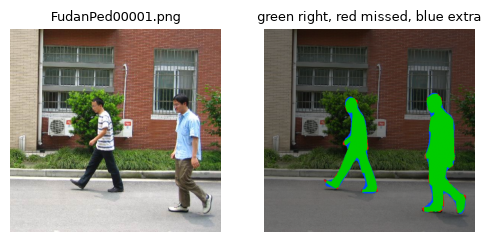

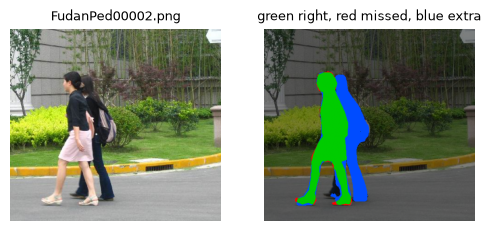

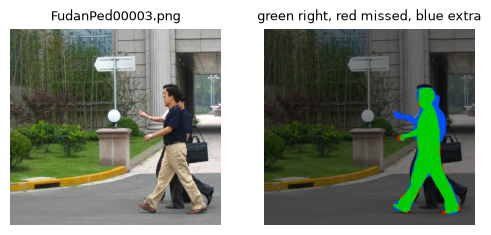

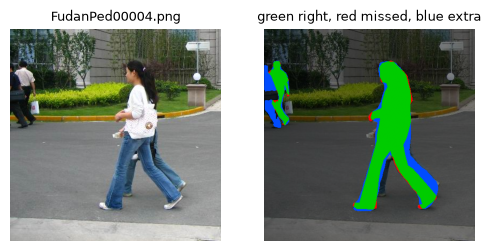

In [31]:
for name in truth:
    p = segment(photos[name], what, model, threshold)
    g = truth[name]
    view = photos[name].astype(float) / 255 * 0.5
    view[p & g] = [0, 0.8, 0]
    view[g & ~p] = [1, 0, 0]
    view[p & ~g] = [0, 0.3, 1]
    show([photos[name], view], [name, "green right, red missed, blue extra"], size=3)

**Questions for your presentation:** Which model and threshold are best
for your app? Where do the masks go wrong - the edges, small objects, hidden
objects? Are the red and blue areas mistakes of the model, or of your painting?
Is the area error small enough for your user?

### Your evaluation conclusions

For this project, I created a simple segmentation app that measures how much
 of a photo is covered by people. I tested two models, Mask R-CNN (COCO) and CLIPSeg (text), using four example photos with ground-truth masks.

**Results:**

- Mask R-CNN achieved a mean IoU of **0.76** with thresholds 0.5 and 0.7.
- The mean area error was **2.5 percentage points** for both thresholds.
- CLIPSeg performed worse. Its best mean IoU was **0.60** at threshold 0.3, with an area error of 4.9 percentage points.
- The best individual result was photo 1, with an IoU of 0.90. Photo 2 was the most difficult, with an IoU of 0.58.

**Conclusion:**

Mask R-CNN performed better than CLIPSeg for detecting people. I would choose Mask R-CNN with a threshold of 0.5 because it achieved the joint-best results and is already the default setting.

The model sometimes overestimated the area covered by people. This shows that segmentation is useful for estimating how much of an image contains people, but it is not always completely accurate.

The evaluation was based on only four labelled photos, so more testing would be needed before using the app in real situations.

## 8. End result and presentation checklist

Make the pictures for your slides with `save_result("name.png")` (in the same
cell as the picture) and download them all with `download_results()`.

| Part of your presentation | Where in this notebook | Done? |
|---------------------------|------------------------|-------|
| 1. What is the technique? input, output, what is it for | section 1 | |
| 2. Which data processing is needed? photo -> model, and the ground truth | sections 4 and 6 | |
| 3. What did you do? your idea, your photos, how you built your MVP | sections 3 and 5 | |
| 4. How do you evaluate it? metric, why, your result | section 7 | |
| 5. The end result: your MVP working, and where it fails | section 8 | |
| Extra: which model is better for your object, and why? | section 7 | |

Also prepare an answer to: **who could this app fail, and who could be harmed
by it?** The class will ask.

### Who could this app fail, and who could be harmed by it?

This app could fail when people are partly hidden, far away or standing in poor lighting. It might also make mistakes when people are close together.

People who use the app to measure how crowded a place is could receive incorrect information. For example, a school could underestimate how busy a hallway is.

There are also privacy risks when using photos of people without their permission.

To reduce these risks, the app should be tested on more different photos, and people's privacy should always be respected.

People cover 20.3% of the photo.
saved results/result_000000013659.png


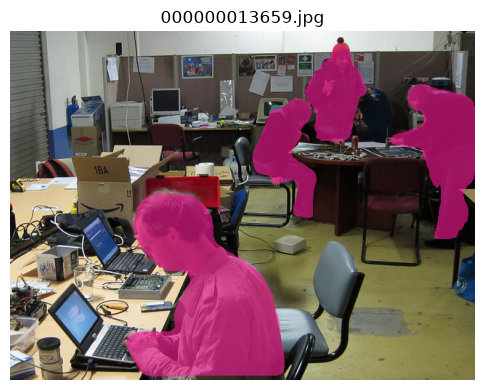

People cover 4.0% of the photo.
saved results/result_000000087038.png


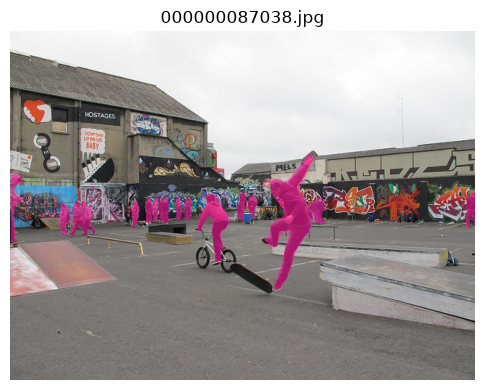

In [32]:
# The end result: your app on two photos - saved for the slides
for name in list(photos)[:2]:
    print(my_app(photos[name], name))
    save_result("result_" + os.path.splitext(name)[0] + ".png")
    plt.show()
# download_results()